This notebook will serve to generate bathymetric surfaces using a TIN method for synthetic SBES, then compare the errors back to MBES.

Error analysis should be done using:
1. Different SBES inter-track sounding spacing
2. Different SBES trackline spacing
3. In the context of bed complexity (e.g., Morphological Variation Index and/or Terrain Ruggedness Index by Wilson)

In [1]:
%reload_ext autoreload
%autoreload 2
import os
import sys
sys.path.insert(0, os.path.abspath('../src'))
import pandas as pd
import geopandas as gpd
from pathlib import Path
import matplotlib.pyplot as plt

from interpolators.TIN import TIN

import processing_help
import numpy as np

import xdem
import libpysal as ps
import esda

np.random.seed(1337)

import warnings
# remove future warning of spline mindist since we aren't even providing it anyways
warnings.filterwarnings('ignore', message='.*mindist parameter.*', category=FutureWarning)     

In [2]:
WORK_DIR = Path('/mnt/teamgroup/AutoDBM/Public')
CRS = pd.read_csv(WORK_DIR / 'survey_CRS_list.csv')
crs_data = WORK_DIR / 'survey_CRS_list.csv'
mbes = list((WORK_DIR / 'Multibeam_Validation_Points_For_Distribution').glob('*.csv'))
sbes = list((WORK_DIR / 'Synthetic_Singlebeam_Surveys_For_Distribution').glob('*.csv'))

In [15]:
# Build a boundary catalog from SurveyJob layers, then match each survey to the best boundary by SurveyId
data_pairs = {}

def _norm(s):
    return "".join(ch for ch in str(s).upper() if ch.isalnum())

def _tokens(s):
    return {t for t in str(s).upper().replace("-", "_").split("_") if t}

# 1) Read all boundary candidates once
boundary_catalog = []
for gdb_file in WORK_DIR.glob("*/*.gdb"):
    try:
        sj = gpd.read_file(gdb_file, layer="SurveyJob")
    except Exception:
        continue

    if "SurveyId" not in sj.columns or sj.empty:
        continue

    # keep one record per SurveyId (first occurrence)
    for sid, grp in sj.groupby("SurveyId", dropna=True):
        boundary_catalog.append({
            "survey_id": str(sid),
            "survey_norm": _norm(sid),
            "survey_tokens": _tokens(sid),
            "gdb_file": gdb_file,
            "boundary": grp.copy()
        })

# 2) Match each survey from CRS table to best boundary
for _, items in pd.read_csv(crs_data).iterrows():
    survey = items["Survey"]

    sbes_match = [p for p in sbes if survey in str(p)]
    mbes_match = [p for p in mbes if survey in str(p)]
    if not sbes_match or not mbes_match:
        print(f"Missing SBES/MBES file for: {survey}")
        continue

    s_norm = _norm(survey)
    s_tokens = _tokens(survey)

    # exact normalized SurveyId match first
    exact = [c for c in boundary_catalog if c["survey_norm"] == s_norm]

    if exact:
        best = exact[0]
    else:
        # fallback: token overlap score
        scored = []
        for c in boundary_catalog:
            inter = len(s_tokens & c["survey_tokens"])
            denom = max(1, len(s_tokens))
            score = inter / denom
            scored.append((score, c))
        scored.sort(key=lambda x: x[0], reverse=True)
        best = scored[0][1] if scored and scored[0][0] > 0 else None

    if best is None:
        print(f"No boundary found for: {survey}")
        continue

    boundary = best["boundary"]
    data_pairs[survey] = [
        sbes_match[0],
        mbes_match[0],
        boundary,
    ]

    print(f"{survey} -> {best['survey_id']} ({best['gdb_file'].name})")

AK_08_WES_20160318_CS_FULL -> AK_08_WES_20160318_CS (AK_08_WES_20160318_CS.gdb)
BR_02_JEC_20260211_CS -> BR_02_JEC_20260211_CS (BR_02_JEC_20260211_CS.gdb)
CB_02_CB2_20260202_CS_A -> CB_02_CB2_20260202_CS (CB_02_CB2_20260202_CS.gdb)
CC_05_HLQ_20260205_XC -> CC_05_HLQ_20260205_XC (CC_05_HLQ_20260205_XC.gdb)
CH_02_CHL_20220210_CS_FULL -> CH_02_CHL_20220210_CS (CH_02_CHL_20220210_CS.gdb)
CL_02_UDS_20260305_CS_A -> CL_02_UDS_20260305_CS (CL_02_UDS_20260305_CS.gdb)
CR_ND_BL5_20220301_CS_102_103_SORT -> CR_ND_BL5_20220301_CS_102_103_SORT (CR_ND_BL5_20220301_CS_102_103_SORT.gdb)
DU_02_EWW_20260211_CS_E_12_6_1_67 -> DU_02_EWW_20260211_CS_E_12_6_1_67 (DU_02_EWW_20260211_CS_E_12_6_1_67.gdb)
FR_6A_SCL_20240401_CS -> FR_6A_SCL_20240401_CS (FR_6A_SCL_20240401_CS.gdb)
GH_03_COC_20251202_CS_E_5_13_439 -> GH_03_COC_20251202_CS_E_5_13_439 (GH_03_COC_20251202_CS_E_5_13_439.gdb)
GW_68_CSL_20250909_CS_3X3_A -> GW_68_CSL_20250909_CS_3X3 (GW_68_CSL_20250909_CS_3X3.gdb)
IL_LA_MVR_20251118_CS_14001420_25D_A ->

In [16]:
survey_mbes = {}
survey_sbes = {}

for survey in list(data_pairs.keys()):
    survey_mbes[survey] = list(WORK_DIR.glob(f'{survey}/*MBES*.tif'))
    survey_sbes[survey] = list(WORK_DIR.glob(f'{survey}/*SBES*.tif'))

In [17]:
geojson = Path(os.getcwd()).parent / 'shapefiles' / 'National_Channel_Framework_-6742069550782745925.geojson'
ncf = gpd.read_file(geojson)

# Recreate Figure 4: Aggregated Error Metrics based on sounding and trackline spacings

In [ ]:
records = []
for survey in data_pairs:
    mbes_dbm = xdem.DEM(survey_mbes[survey][0])

    for tif in survey_sbes[survey]:
        if tif.stem == 'SBES_TIN_bathy':
            continue
        ddbm = mbes_dbm - xdem.DEM(tif).reproject(mbes_dbm)
        ts, ss = tif.stem[5:-10].split('_')
        records.append({
            'Track_Spacing': ts,
            'Sounding_Spacing': ss,
            'MAE': np.mean(np.abs(ddbm)),
            'RMSE': ddbm.get_stats('rmse'),
            # 'NMAD': ddbm.get_stats('nmad'),
            '95_Percentile': np.percentile(np.abs(ddbm), 95),
        })

df = pd.DataFrame(records)
mean_agg_df = df.groupby(['Track_Spacing', 'Sounding_Spacing']).mean().reset_index()
med_agg_df = df.groupby(['Track_Spacing', 'Sounding_Spacing']).median().reset_index()

In [ ]:
# Make sure spacing columns are numeric for correct ordering
mean_agg_df['Track_Spacing'] = mean_agg_df['Track_Spacing'].astype(float)
mean_agg_df['Sounding_Spacing'] = mean_agg_df['Sounding_Spacing'].astype(float)

metrics = [
    ('MAE', 'Global MAE', 'Blues', 'MAE (ft)'),
    ('RMSE', 'Global RMSE', 'Oranges', 'RMSE (ft)'),
    ('95_Percentile', '95th Percentile of |Error|', 'Purples', '95th percentile (ft)'),
]

fig, axes = plt.subplots(1, 3, figsize=(12, 5), dpi=500)

for ax, (col, title, cmap, cbar_label) in zip(axes, metrics):
    # rows = transect (track) spacing descending, cols = point (sounding) spacing ascending
    grid = mean_agg_df.pivot(index='Track_Spacing',
                        columns='Sounding_Spacing',
                        values=col).sort_index(ascending=False)

    im = ax.imshow(grid.values, cmap=cmap, aspect='auto')

    norm = im.norm  # maps data values to 0–1
    # annotate each cell
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            val = grid.values[r, c]
            if not np.isnan(val):
                color = 'white' if norm(val) > 0.65 else 'black'
                ax.text(c, r, f'{val:.2f}', ha='center', va='center',
                        fontsize=12, color=color)

    ax.set_xticks(range(grid.shape[1]))
    ax.set_xticklabels([f'{int(x)}' for x in grid.columns], fontsize=12)
    ax.set_yticks(range(grid.shape[0]))
    ax.set_yticklabels([f'{int(y)}' for y in grid.index], rotation='vertical', fontsize =12)
    ax.set_title(title, fontsize=15, fontweight='bold')
    ax.set_xlabel('Point spacing on transect (ft)', fontweight='bold', fontsize =12)
    ax.set_ylabel('Transect spacing (ft)', fontweight='bold', fontsize =12)

    cbar = fig.colorbar(im, ax=ax, orientation='horizontal',
                        pad=0.16, fraction=0.05)
    cbar.set_label(cbar_label, fontweight='bold', fontsize=12)

plt.tight_layout()
# plt.savefig('error_heatmaps.png', dpi=500, bbox_inches='tight')
plt.show()

In [ ]:
# Make sure spacing columns are numeric for correct ordering
med_agg_df['Track_Spacing'] = med_agg_df['Track_Spacing'].astype(float)
med_agg_df['Sounding_Spacing'] = med_agg_df['Sounding_Spacing'].astype(float)

metrics = [
    ('RMSE', 'Global RMSE', 'Oranges', 'RMSE (ft)'),
    ('NMAD', 'Global NMAD', 'Blues', 'NMAD (ft)'),         
    ('95_Percentile', '95th Percentile of |Error|', 'Purples', '95th percentile (ft)'),
]

fig, axes = plt.subplots(1, 3, figsize=(12, 5), dpi=500)

for ax, (col, title, cmap, cbar_label) in zip(axes, metrics):
    # rows = transect (track) spacing descending, cols = point (sounding) spacing ascending
    grid = med_agg_df.pivot(index='Track_Spacing',
                        columns='Sounding_Spacing',
                        values=col).sort_index(ascending=False)

    im = ax.imshow(grid.values, cmap=cmap, aspect='auto')

    norm = im.norm  # maps data values to 0–1
    # annotate each cell
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            val = grid.values[r, c]
            if not np.isnan(val):
                color = 'white' if norm(val) > 0.65 else 'black'
                ax.text(c, r, f'{val:.2f}', ha='center', va='center',
                        fontsize=12, color=color)

    ax.set_xticks(range(grid.shape[1]))
    ax.set_xticklabels([f'{int(x)}' for x in grid.columns], fontsize=12)
    ax.set_yticks(range(grid.shape[0]))
    ax.set_yticklabels([f'{int(y)}' for y in grid.index], rotation='vertical', fontsize =12)
    ax.set_title(title, fontsize=15, fontweight='bold')
    ax.set_xlabel('Point spacing on transect (ft)', fontweight='bold', fontsize =12)
    ax.set_ylabel('Transect spacing (ft)', fontweight='bold', fontsize =12)

    cbar = fig.colorbar(im, ax=ax, orientation='horizontal',
                        pad=0.16, fraction=0.05)
    cbar.set_label(cbar_label, fontweight='bold', fontsize=12)

plt.tight_layout()
# plt.savefig('error_heatmaps.png', dpi=500, bbox_inches='tight')
plt.show()

# Second Error Metric Analysis: Dredge Cut Volumes
- $/CY can range between something like $10/CY and $40/CY

Survey: CL_02_UDS_20260305_CS_A


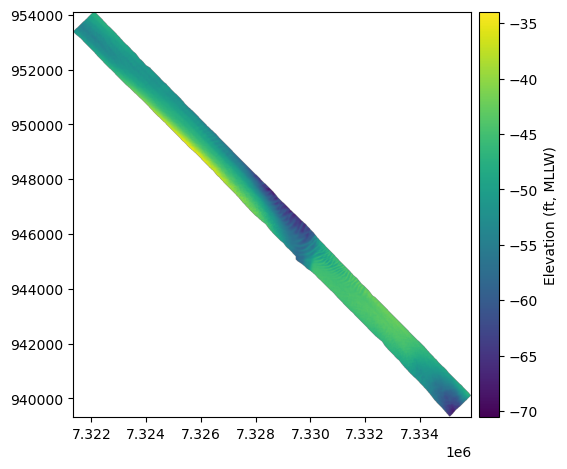

In [18]:
# survey = list(survey_mbes.keys())[2]
survey = "CL_02_UDS_20260305_CS_A"

print("Survey:",survey)

mbes_dbm = xdem.DEM(survey_mbes[survey][0])
mbes_dbm.plot(
        cmap="viridis",
        vmin=float(mbes_dbm.get_stats("min")),
        vmax=float(mbes_dbm.get_stats("max")),
        cbar_title="Elevation (ft, MLLW)",
)

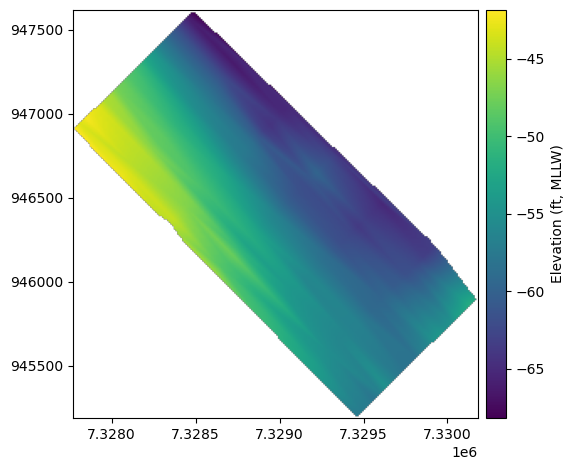

In [36]:
# clipped_sbes_dbms = list(Path(f'/mnt/teamgroup/AutoDBM/Public/{survey}').glob('clipped_SBES*'))
track_spacing = 400
sounding_spacing = 50

sbes_dbm = xdem.DEM(f'/mnt/teamgroup/AutoDBM/Public/{survey}/clipped_SBES_{track_spacing}_{sounding_spacing}_TIN_bathy.tif')
# sbes_dbm = xdem.DEM(clipped_sbes_dbms[2])
sbes_dbm.plot(
        cmap="viridis",
        vmin=float(sbes_dbm.get_stats("min")),
        vmax=float(sbes_dbm.get_stats("max")),
        cbar_title="Elevation (ft, MLLW)",
)

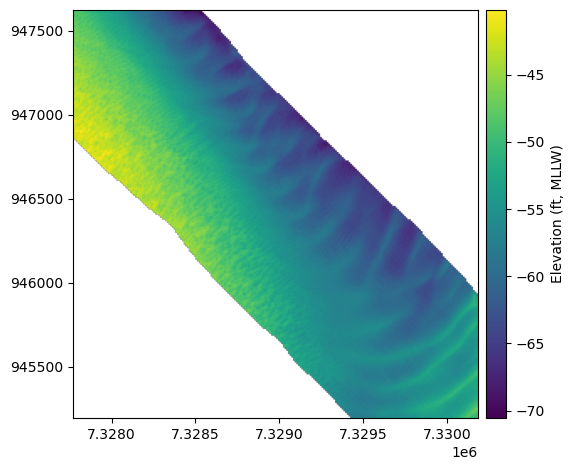

In [37]:
clipped_mbes_dbm = mbes_dbm.crop(sbes_dbm, inplace=False)
clipped_mbes_dbm.plot(
        cmap="viridis",
        vmin=float(clipped_mbes_dbm.get_stats("min")),
        vmax=float(clipped_mbes_dbm.get_stats("max")),
        cbar_title="Elevation (ft, MLLW)",
)

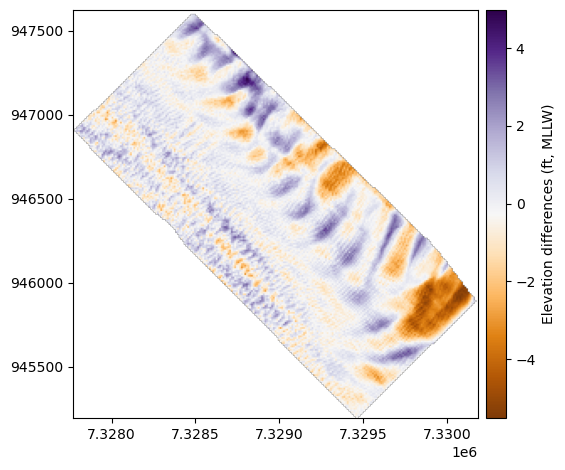

In [38]:
ddbm=clipped_mbes_dbm - sbes_dbm.reproject(clipped_mbes_dbm)
ddbm.plot(
        cmap="PuOr",
        vmin=float(ddbm.get_stats("min")),
        vmax=float(ddbm.get_stats("max")),
        cbar_title="Elevation differences (ft, MLLW)",
)

In [39]:
tgt_ncf = ncf[ncf['channelareaidfk'].str.contains(f'{survey[:9]}')]
tgt_ncf

,OBJECTID,channelreachidpk,channelareaidfk,sdsfeaturedescription,mediaidfk,sdsid,sdsmetadataid,sourceprojection,mileagestart,mileageend,...,dateuploaded,sourceagency,usacedistrictcode,dateloadedenterprise,projectedarea,areasizeuom,channelreachcategory,channelreachtype,epsg,geometry
6736,6737,CENWP_CL_02_UDS_1,CENWP_CL_02_UDS,Upper Desdemona Shoal,NCF_CENWP_DIS_OREGON_NORTH_20250617.ZIP,2848b3e0-df42-43c9-aa51-f70115d42857,NCF_CENWP_DIS_OREGON_NORTH_20250617.ZIP,NAD_1983_StatePlane_Oregon_North_FIPS_3601_Feet,6.4,10.0,...,"Tue, 17 Jun 2025 00:00:00 GMT",CENWP_DIS,CENWP,"Tue, 17 Jun 2025 13:30:54 GMT",1.151439e+07,Square Foot,NCF,fixed,102726,"POLYGON ((-123.92373 46.19403, -123.92413 46.1..."


In [62]:
# auth_depth = tgt_ncf.depthauthorized
auth_depth = float(tgt_ncf["depthauthorized"].iloc[0])
cut = auth_depth + clipped_mbes_dbm.data
cut = np.where(cut > 0, cut, 0.0)
cut[np.isnan(clipped_mbes_dbm.data)] = 0.0

px, py = abs(clipped_mbes_dbm.transform.a), abs(clipped_mbes_dbm.transform.e)
volume_ft3 = np.nansum(cut) * px * py
volume_cy = volume_ft3 / 27.0
print(f"{volume_cy:,.2f} CY")

# # if statement returns posterior lower bound, prediction, and posterior upper bound dredge cut estimates
# if "GP" in str(tif_path):
#     unc_tif_path = Path(str(tif_path).replace('bathy', 'uncertainty'))
#     with rasterio.open(unc_tif_path) as unc_src:
#         unc_out_image, _ = mask(unc_src, polygon_gdf.geometry.values,
#                                     crop=True, filled=True, nodata=np.nan)
#         unc_data = unc_out_image[0].astype("float64")
#         if unc_src.nodata is not None:
#             unc_data[unc_data == unc_src.nodata] = np.nan
    
#     # upper bound depth+uncertainty
#     data_up = clipped_mbes_dbm.data + unc_data
#     cut_up = auth_depth - data_up
#     cut_up = np.where(cut_up > 0, cut_up, 0.0)
#     cut_up[np.isnan(data_up)] = 0.0
#     volume_ft3_up = np.nansum(cut_up) * px * py

#     # lower bound depth+uncertainty
#     data_low = clipped_mbes_dbm.data - unc_data
#     cut_low = auth_depth - data_low
#     cut_low = np.where(cut_low > 0, cut_low, 0.0)
#     cut_low[np.isnan(data_low)] = 0.0
#     volume_ft3_low = np.nansum(cut_low) * px * py

1,686.21 CY


In [ ]:
unit = "yd"

reach_vols = {}

for id, geom in tgt_ncf.iterrows():
    reachid = geom.channelreachidpk
    reach_auth_depth = geom.depthauthorized
    # print(reach_auth_depth)
    reach_vols[reachid] = {name: processing_help.compute_volume(path, tgt_ncf, auth_depth = reach_auth_depth, unit = unit) for name, path in methods.items()}

for reach, volumes in reach_vols.items():
    print(f'\n{reach}')
    print("_"*50)
    for key, value in volumes.items():
        print(f'{key}: {value:,.1f} {unit}³')

In [ ]:
records = []

for tif in list(Path(f'/mnt/teamgroup/AutoDBM/Public/{survey}').glob('clipped_SBES*')):
    sbes_dbm = xdem.DEM(tif).reproject(mbes_dbm)



In [ ]:
records = []
for survey in data_pairs:
    mbes_dbm = xdem.DEM(survey_mbes[survey][0])

    for tif in survey_sbes[survey]:
        if tif.stem == 'SBES_TIN_bathy':
            continue
        sbes_dbm = xdem.DEM(tif).reproject(mbes_dbm)
        

In [ ]:
mbes_dbm = xdem.DEM(survey_mbes[survey][0])

    for tif in survey_sbes[survey]:
        if tif.stem == 'SBES_TIN_bathy':
            continue
        sbes_dbm = xdem.DEM(tif).reproject(mbes_dbm)

In [ ]:
methods = {"MBES": mbes_tin_path ,'SBES': sbes_tin_path}
tgt_ncf = ncf[ncf['channelareaidfk'].str.contains(f'{survey[:9]}')]
tgt_ncf

In [ ]:
unit = "yd"

reach_vols = {}

for id, geom in tgt_ncf.iterrows():
    reachid = geom.channelreachidpk
    reach_auth_depth = geom.depthauthorized
    # print(reach_auth_depth)
    reach_vols[reachid] = {name: processing_help.compute_volume(path, tgt_ncf, auth_depth = reach_auth_depth, unit = unit) for name, path in methods.items()}

for reach, volumes in reach_vols.items():
    print(f'\n{reach}')
    print("_"*50)
    for key, value in volumes.items():
        print(f'{key}: {value:,.1f} {unit}³')

In [ ]:
# Differences
for reach, volumes in reach_vols.items():
    print(f'\n{reach}')
    print(f"_"*50)
    for a, b in [('MBES', 'SBES')]:
        diff = volumes[a] - volumes[b]
        print(f'{a} - {b}: {diff:,.1f} {unit}³')

# Third Error Metric Analysis: Bed Complexity
- Terrain Ruggedness Index from Wilson, 2007 | $tri_{\textrm{Wilson}} = \textrm{mean}_{ij} (|h_{00} - h_{ij}|) .$

In [ ]:
def get_error_tri(survey_entry: list | None = None):
    import matplotlib.pyplot as plt

    if survey_entry is None:
        raise ValueError("survey_entry is required")

    mbes_tin_path = survey_entry[0]
    sbes_tin_path = survey_entry[1]

    mbes_dbm = xdem.DEM(mbes_tin_path)

    sbes_dbm = xdem.DEM(sbes_tin_path)
    sbes_dbm = sbes_dbm.reproject(mbes_dbm)

    ddbm = mbes_dbm - sbes_dbm
    ddbm_stats = ddbm.get_stats()

    ddbm_abs = np.abs(ddbm)
    ddbm_abs_stats = ddbm_abs.get_stats()

    tri = mbes_dbm.terrain_ruggedness_index(method="Wilson", window_size=3)

    fig, ax = plt.subplots(1,3, figsize=(15,30), dpi = 300)
    tri.plot(ax=ax[0], cmap="Purples", cbar_title="Terrain ruggedness index (ft)")

    ddbm.plot(
        ax=ax[1],
        cmap="PuOr",
        vmin=float(ddbm_stats["Min"]),
        vmax=float(ddbm_stats["Max"]),
        cbar_title="Elevation differences (ft, MLLW)",
    )

    ddbm_abs.plot(
        ax=ax[2],
        cmap="PuOr",
        vmin=float(ddbm_abs_stats["Min"]),
        vmax=float(ddbm_abs_stats["Max"]),
        cbar_title="Absolute Elevation differences (ft, MLLW)",
    )

    return mbes_dbm, sbes_dbm, ddbm, ddbm_abs, tri, fig

In [ ]:
survey = list(data_pairs.keys())[15]

mbes_dbm, sbes_dbm, ddbm, ddbm_abs, tri, _ = get_error_tri(data_pairs[survey])

### Some Ideas:
1. OLS or GWR to relate the error with the TRI to show how error is SBES relates with TRI
3. Spatial GLM to do the same as 1, but also including the spacing in soundings
2. Getis-Ord G statistic for hot and cold spots in errors, relate this back to TRI


In [ ]:
from rasterio.transform import from_origin

data = tri.data
transform = tri.transform
width, height = data.shape[1], data.shape[0]

# Initialize lists to store coordinates
x_coords = []
y_coords = []

# Loop through each pixel in the raster
for row in range(height):
    for col in range(width):
        # Calculate x and y using the transform
        x, y = transform * (col + 0.5, row + 0.5)  # Adding 0.5 to get the center of the pixel
        x_coords.append(x)
        y_coords.append(y)

x_coords_array = np.array(x_coords).reshape(height, width)
y_coords_array = np.array(y_coords).reshape(height, width)

In [ ]:
y_arr = ddbm.data.data
x_arr = tri.data.data
mask = ddbm.data.mask & tri.data.mask

# Coordinates of valid cells (projected map units)
xs, ys = np.meshgrid(x_coords_array, y_coords_array)
coords = np.column_stack([xs[mask], ys[mask]])

y = np.abs(y_arr[mask]).reshape(-1, 1)   # |residual| as the response
X = x_arr[mask].reshape(-1, 1)           # TRI as predictor

# 3. Standardize X (recommended for GWR stability)
X = (X - X.mean()) / X.std()

In [ ]:
sbes_gdf

In [ ]:
plt.hist(sbes_gdf.Length_along_transect_ft)

In [ ]:
# TODO: Make a function to sample based on "Length_along_transect_ft"